# Problema 3 — Planejamento de Capacidade de Servidores
**Projeto de Métodos Numéricos — 2º GQ**

## Objetivo
A empresa possui capacidade atual de **600 TB**. Usaremos os 12 registros históricos para modelar o crescimento do armazenamento, estimar o próximo mês e identificar quando a demanda ultrapassa a capacidade atual e cada opção de expansão.

Os dados dos CSVs foram mantidos conforme os arquivos fornecidos no repositório do professor.

## 1. Bibliotecas e métodos do pacote

In [18]:
from pathlib import Path
import sys

# Localiza a raiz do projeto
PASTA_PROJETO = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "metodos").is_dir()),
    None
)

if PASTA_PROJETO is None:
    raise FileNotFoundError("A pasta 'metodos' não foi encontrada.")

# Adiciona a raiz ao caminho de busca do Python
sys.path.insert(0, str(PASTA_PROJETO))


# Bibliotecas utilizadas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.options.display.float_format = '{:.2f}'.format

# Métodos implementados pela equipe
from metodos.min_quadrados import ajuste_polinomial_minimos_quadrados
from metodos.lagrange import interpolacao_lagrange

# Define a raiz do repositório
RAIZ = PASTA_PROJETO

# Localiza o CSV
def localizar_arquivo(nome):
    candidatos = [
        RAIZ / nome,
        RAIZ / "dados" / nome,
        RAIZ.parent / nome,
        RAIZ.parent / "dados" / nome,
    ]

    for caminho in candidatos:
        if caminho.exists():
            return caminho

    raise FileNotFoundError(
        f"Não encontrei {nome}. Verifique se o CSV está na raiz do repositório ou em dados/."
    )

plt.style.use("default")

## 2. Leitura dos arquivos

In [19]:
arquivo_armazenamento = localizar_arquivo("armazenamento.csv")
arquivo_expansoes = localizar_arquivo("expansoes.csv")

armazenamento = pd.read_csv(arquivo_armazenamento)
expansoes = pd.read_csv(arquivo_expansoes)

display(armazenamento)
display(expansoes)


,mes,armazenamento_tb
0,1,137.99
1,2,150.45
2,3,172.59
3,4,199.09
4,5,219.06
5,6,250.06
6,7,292.32
7,8,328.07
8,9,366.12
9,10,417.17


,plano,capacidade_adicional_tb
0,A,100
1,B,200
2,C,300


## 3. Conferência e preparação dos dados

In [20]:
colunas_armazenamento = {"mes", "armazenamento_tb"}
colunas_expansoes = {"plano", "capacidade_adicional_tb"}
if not colunas_armazenamento.issubset(armazenamento.columns):
    raise ValueError(f"Colunas esperadas em armazenamento.csv: {colunas_armazenamento}")
if not colunas_expansoes.issubset(expansoes.columns):
    raise ValueError(f"Colunas esperadas em expansoes.csv: {colunas_expansoes}")

armazenamento["mes"] = pd.to_numeric(armazenamento["mes"], errors="raise")
armazenamento["armazenamento_tb"] = pd.to_numeric(armazenamento["armazenamento_tb"], errors="raise")
expansoes["capacidade_adicional_tb"] = pd.to_numeric(expansoes["capacidade_adicional_tb"], errors="raise")
armazenamento = armazenamento.sort_values("mes").reset_index(drop=True)

if armazenamento.isna().any().any() or expansoes.isna().any().any():
    raise ValueError("Existem valores ausentes nos arquivos CSV.")
if armazenamento["mes"].duplicated().any():
    raise ValueError("Existem meses duplicados.")
if (armazenamento["armazenamento_tb"] < 0).any() or (expansoes["capacidade_adicional_tb"] < 0).any():
    raise ValueError("Capacidades não podem ser negativas.")
if len(armazenamento) < 3:
    raise ValueError("São necessários ao menos três meses para o ajuste quadrático.")

display(armazenamento.isna().sum().to_frame("valores_ausentes"))
display(expansoes)

,valores_ausentes
mes,0
armazenamento_tb,0


,plano,capacidade_adicional_tb
0,A,100
1,B,200
2,C,300


## 4. Análise descritiva do armazenamento

In [21]:
meses = armazenamento["mes"].to_numpy(dtype=float)
valores = armazenamento["armazenamento_tb"].to_numpy(dtype=float)
primeiro_valor = valores[0]
ultimo_valor = valores[-1]
crescimento_absoluto = ultimo_valor - primeiro_valor
crescimento_percentual = crescimento_absoluto / primeiro_valor * 100

print(f"Meses observados: {len(valores)}")
print(f"Armazenamento no mês {int(meses[0])}: {primeiro_valor:.2f} TB")
print(f"Armazenamento no mês {int(meses[-1])}: {ultimo_valor:.2f} TB")
print(f"Crescimento absoluto: {crescimento_absoluto:.2f} TB")
print(f"Crescimento percentual: {crescimento_percentual:.2f}%")
display(armazenamento["armazenamento_tb"].describe().to_frame("armazenamento_tb"))

Meses observados: 12
Armazenamento no mês 1: 137.99 TB
Armazenamento no mês 12: 519.14 TB
Crescimento absoluto: 381.15 TB
Crescimento percentual: 276.22%


,armazenamento_tb
count,12.00
mean,293.02
std,126.99
min,137.99
25%,192.47
50%,271.19
75%,378.88
max,519.14


## 5. Variação mensal e visualização

,mes,armazenamento_tb,aumento_tb,aumento_percentual
0,1,137.99,NaN,NaN
1,2,150.45,12.46,9.03
2,3,172.59,22.14,14.72
3,4,199.09,26.50,15.35
4,5,219.06,19.97,10.03
5,6,250.06,31.00,14.15
6,7,292.32,42.26,16.90
7,8,328.07,35.75,12.23
8,9,366.12,38.05,11.60
9,10,417.17,51.05,13.94


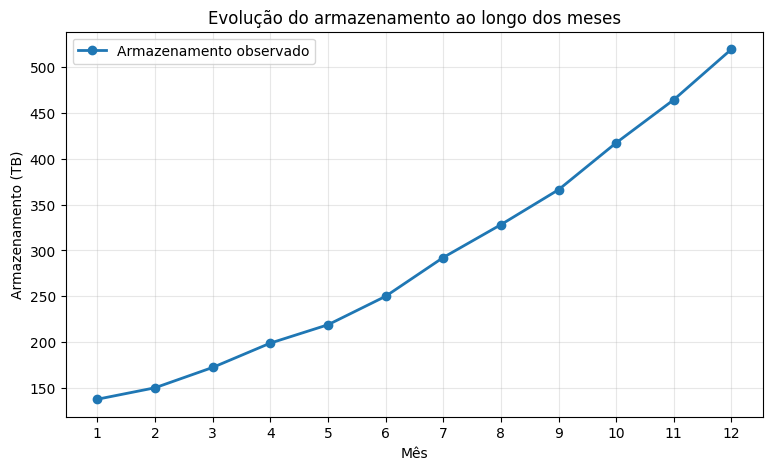

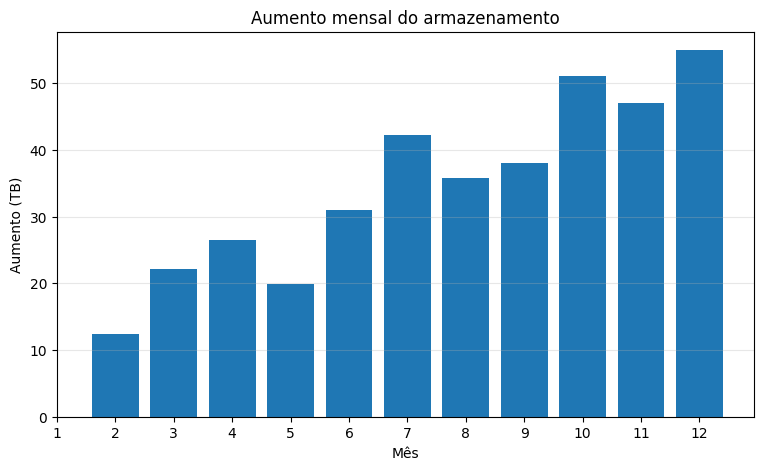

In [22]:
armazenamento["aumento_tb"] = armazenamento["armazenamento_tb"].diff()
armazenamento["aumento_percentual"] = armazenamento["armazenamento_tb"].pct_change() * 100
display(armazenamento)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(meses, valores, marker="o", linewidth=2, label="Armazenamento observado")
ax.set(title="Evolução do armazenamento ao longo dos meses", xlabel="Mês", ylabel="Armazenamento (TB)")
ax.set_xticks(meses); ax.grid(True, alpha=0.3); ax.legend(); plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(armazenamento["mes"], armazenamento["aumento_tb"])
ax.set(title="Aumento mensal do armazenamento", xlabel="Mês", ylabel="Aumento (TB)")
ax.set_xticks(meses); ax.grid(axis="y", alpha=0.3); plt.show()

## 6. Métodos numéricos utilizados

As implementações dos métodos numéricos foram organizadas em módulos Python separados, facilitando sua reutilização e manutenção.

- **Sistema linear:** eliminação de Gauss com pivoteamento parcial.
- **Interpolação:** polinômio de Lagrange.
- **Aproximação:** mínimos quadrados para ajustar um polinômio de segundo grau.

O notebook importa essas implementações e aplica os métodos aos dados do Problema 3.

### 6.1 Sistema linear e aproximação por mínimos quadrados

In [23]:
def avaliar_polinomio(coeficientes, x):
    return sum(
        coef * x**i
        for i, coef in enumerate(coeficientes)
    )

# Ajuste de grau 2: p(m) = a0 + a1*m + a2*m².
grau = 2
coef = ajuste_polinomial_minimos_quadrados(meses, valores, grau=grau)
a0, a1, a2 = coef

valores_ajustados = avaliar_polinomio(coef, meses)
residuos = valores - valores_ajustados
sse = float(np.sum(residuos**2))
sst = float(np.sum((valores - np.mean(valores))**2))
r2 = 1 - sse/sst

print("Coeficientes em ordem crescente:")
print(f"a0 = {a0:.8f}")
print(f"a1 = {a1:.8f}")
print(f"a2 = {a2:.8f}")
print(f"R² = {r2:.6f}")
print(f"Modelo: p(m) = {a0:.6f} + {a1:.6f}m + {a2:.6f}m²")

Coeficientes em ordem crescente:
a0 = 125.14568182
a1 = 9.92926823
a2 = 1.90765984
R² = 0.999574
Modelo: p(m) = 125.145682 + 9.929268m + 1.907660m²


### 6.2 Interpolação de Lagrange

In [24]:
# Exemplo de interpolação entre os meses 5 e 6 usando três pontos próximos.
indices = [3, 4, 5]  # meses 4, 5 e 6
x_interp = meses[indices]
y_interp = valores[indices]
ponto_intermediario = 5.5
estimativa_interpolada = interpolacao_lagrange(x_interp, y_interp, ponto_intermediario)

print(f"Interpolação de Lagrange em m = {ponto_intermediario}: {estimativa_interpolada:.2f} TB")
print("Esse cálculo estima um valor entre observações; não é usado para extrapolar o mês 13.")

Interpolação de Lagrange em m = 5.5: 233.18 TB
Esse cálculo estima um valor entre observações; não é usado para extrapolar o mês 13.


## 7. Resolução das questões do enunciado

### (a) Função matemática que representa o crescimento

Modelo quadrático obtido por mínimos quadrados:
p(m) = 125.145682 + (9.929268)m + (1.907660)m²
Coeficiente de determinação R² = 0.999574


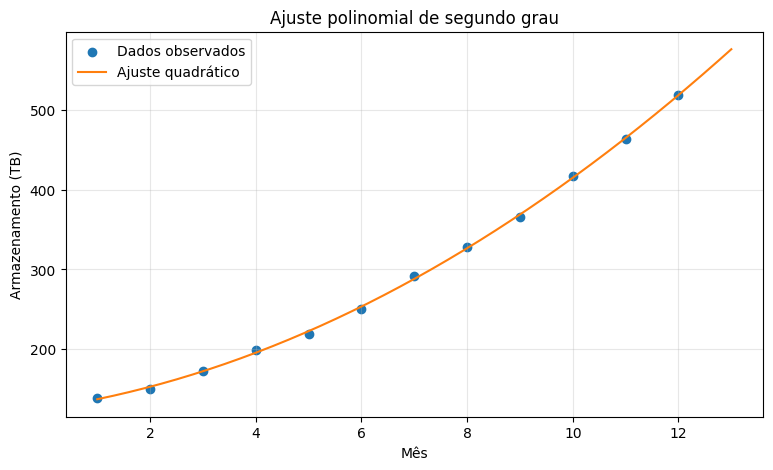

In [25]:
print("Modelo quadrático obtido por mínimos quadrados:")
print(f"p(m) = {a0:.6f} + ({a1:.6f})m + ({a2:.6f})m²")
print(f"Coeficiente de determinação R² = {r2:.6f}")

fig, ax = plt.subplots(figsize=(9, 5))
m_plot = np.linspace(meses.min(), 13, 200)
ax.scatter(meses, valores, label="Dados observados")
ax.plot(m_plot, avaliar_polinomio(coef, m_plot), color="tab:orange", label="Ajuste quadrático")
ax.set(title="Ajuste polinomial de segundo grau", xlabel="Mês", ylabel="Armazenamento (TB)")
ax.grid(True, alpha=0.3); ax.legend(); plt.show()

**Interpretação:** escolhemos um polinômio de segundo grau pelo método dos mínimos quadrados. Ele representa a tendência crescente com curvatura observada na série e não precisa passar exatamente por todos os pontos. Os coeficientes são calculados resolvendo o sistema normal por eliminação de Gauss, implementada no pacote. O valor de R² mostra a proporção da variação dos dados explicada pelo ajuste. A escolha é uma aproximação para os dados disponíveis; outros graus poderiam produzir ajustes diferentes.

### (b) Estimativa do volume no próximo mês

In [26]:
mes_proximo = float(meses[-1] + 1)
previsao_proximo_mes = float(avaliar_polinomio(coef, mes_proximo))
print(f"Previsão para o mês {int(mes_proximo)}: {previsao_proximo_mes:.2f} TB")

Previsão para o mês 13: 576.62 TB


### (c) Quando a demanda ultrapassa 600 TB?

In [27]:
capacidade_atual = 600.0

def primeiro_mes_acima(capacidade, coeficientes, inicio, limite=500):
    for mes in range(int(inicio), limite + 1):
        demanda = float(avaliar_polinomio(coeficientes, mes))
        if demanda > capacidade:
            return mes, demanda
    return None, None

mes_600, demanda_600 = primeiro_mes_acima(capacidade_atual, coef, meses[-1] + 1)
print(f"Primeiro mês inteiro em que a estimativa supera 600 TB: mês {mes_600}")
print(f"Demanda estimada nesse mês: {demanda_600:.2f} TB")

Primeiro mês inteiro em que a estimativa supera 600 TB: mês 14
Demanda estimada nesse mês: 638.06 TB


### (d) Quando a capacidade total será ultrapassada em cada plano?

In [28]:
comparacao_planos = expansoes.copy()
comparacao_planos["capacidade_atual_tb"] = capacidade_atual
comparacao_planos["capacidade_total_tb"] = (
    comparacao_planos["capacidade_atual_tb"] + comparacao_planos["capacidade_adicional_tb"]
)

meses_ultrapassagem = []
demandas_ultrapassagem = []
for capacidade in comparacao_planos["capacidade_total_tb"]:
    mes, demanda = primeiro_mes_acima(float(capacidade), coef, meses[-1] + 1)
    meses_ultrapassagem.append(mes)
    demandas_ultrapassagem.append(demanda)

comparacao_planos["primeiro_mes_acima_da_capacidade"] = meses_ultrapassagem
comparacao_planos["demanda_estimada_no_mes_tb"] = demandas_ultrapassagem
display(comparacao_planos)

,plano,capacidade_adicional_tb,capacidade_atual_tb,capacidade_total_tb,primeiro_mes_acima_da_capacidade,demanda_estimada_no_mes_tb
0,A,100,600.00,700.00,15,703.31
1,B,200,600.00,800.00,17,845.26
2,C,300,600.00,900.00,18,921.95


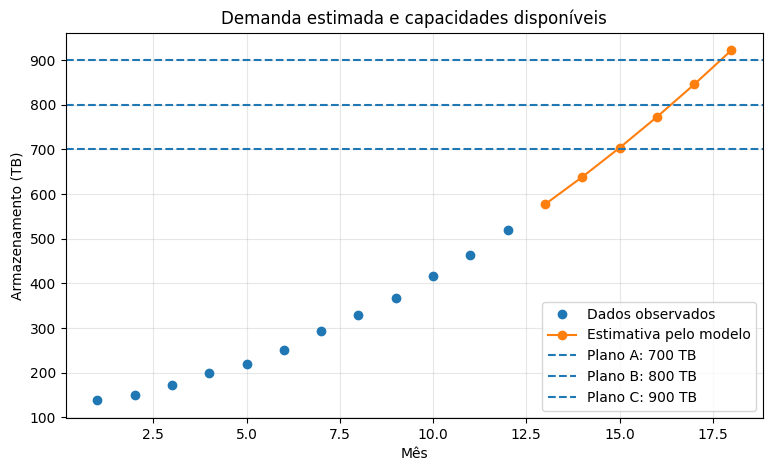

In [29]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(meses, valores, "o", label="Dados observados")
m_futuro = np.arange(13, max(meses_ultrapassagem) + 1)
ax.plot(m_futuro, avaliar_polinomio(coef, m_futuro), marker="o", label="Estimativa pelo modelo")
for _, linha in comparacao_planos.iterrows():
    ax.axhline(linha["capacidade_total_tb"], linestyle="--",
               label=f"Plano {linha['plano']}: {linha['capacidade_total_tb']:.0f} TB")
ax.set(title="Demanda estimada e capacidades disponíveis", xlabel="Mês", ylabel="Armazenamento (TB)")
ax.grid(True, alpha=0.3); ax.legend(); plt.show()

## 8. Conclusão

Os dados mostram que o armazenamento passou de 137,99 TB no primeiro mês para 519,14 TB no décimo segundo, um aumento de 381,15 TB (aproximadamente 276,2%). Para representar a tendência e realizar as estimativas, ajustamos um polinômio quadrático por mínimos quadrados, calculando seus coeficientes por meio de um sistema linear resolvido com eliminação de Gauss.

A previsão do próximo mês e os meses de ultrapassagem são calculados pelo modelo e apresentados nas células anteriores. Considerando a capacidade instalada de 600 TB informada no enunciado, cada plano foi avaliado pela capacidade total resultante da soma entre os 600 TB atuais e o acréscimo de 100, 200 ou 300 TB.

As estimativas dependem da hipótese de que a tendência observada continue. Como se trata de extrapolação de apenas 12 meses de dados, os resultados devem ser usados como apoio ao planejamento e revistos quando novos registros estiverem disponíveis. A escolha definitiva também deve considerar margem de segurança, custos e a possibilidade de mudanças no ritmo de crescimento.

## 9. Limitações e observações

- O modelo quadrático é uma aproximação da tendência observada, não uma garantia de crescimento futuro.
- Os meses de ultrapassagem indicam o primeiro mês inteiro em que a previsão fica acima da capacidade.
- A comparação dos planos considera a capacidade atual de 600 TB somada ao acréscimo de 100, 200 ou 300 TB.